## Chapter 9

### Chapter 9 Exercise 2

grid 64 x 64 , n = 4096 , eps = 0.0008 , steps = 120
S is 4096 x 121


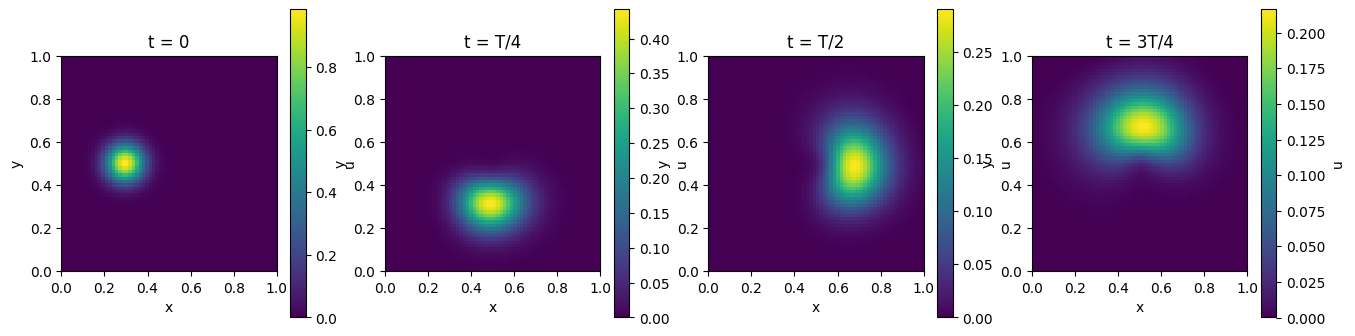

t = 0 : max u = 0.9837
t = T/4 : max u = 0.4418
t = T/2 : max u = 0.2901
t = 3T/4 : max u = 0.2165


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.linalg import splu

nx = 64
h = 1 / (nx + 1)
n = nx * nx
eps = 8e-4
omega = 2 * np.pi
T = 1
steps = 120
dt = T / steps
print("grid", nx, "x", nx, ", n =", n, ", eps =", eps, ", steps =", steps)

grid = np.linspace(h, 1 - h, nx)
xx, yy = np.meshgrid(grid, grid, indexing='ij')
xv = xx.flatten()
yv = yy.flatten()

vx = -omega * (yv - 0.5)
vy = omega * (xv - 0.5)

A = sp.lil_matrix((n, n))
for i in range(nx):
  for j in range(nx):
    k = i * nx + j
    A[k, k] = -4 * eps / (h*h) - abs(vx[k]) / h - abs(vy[k]) / h
    if i > 0:
      A[k, k - nx] = eps / (h*h) + max(vx[k], 0) / h
    if i < nx - 1:
      A[k, k + nx] = eps / (h*h) + max(-vx[k], 0) / h
    if j > 0:
      A[k, k - 1] = eps / (h*h) + max(vy[k], 0) / h
    if j < nx - 1:
      A[k, k + 1] = eps / (h*h) + max(-vy[k], 0) / h

M = sp.identity(n) - dt * A
solver = splu(M.tocsc())

u = np.exp(-((xv - 0.3)*(xv - 0.3) + (yv - 0.5)*(yv - 0.5)) / (2 * 0.06*0.06))
S = np.zeros((n, steps + 1))
S[:, 0] = u
for k in range(steps):
  u = solver.solve(u)
  S[:, k + 1] = u
print("S is", S.shape[0], "x", S.shape[1])

plot_steps = [0, 30, 60, 90]
labels = ["t = 0", "t = T/4", "t = T/2", "t = 3T/4"]
plt.figure(figsize=(16, 4))
for p in range(4):
  plt.subplot(1, 4, p + 1)
  plt.imshow(S[:, plot_steps[p]].reshape(nx, nx).T, origin='lower', extent=[0, 1, 0, 1])
  plt.colorbar(label="u")
  plt.xlabel("x")
  plt.ylabel("y")
  plt.title(labels[p])
plt.show()

for p in range(4):
  print(labels[p], ": max u =", round(np.max(S[:, plot_steps[p]]), 4))

The green blob appears to be moving in a counterclockwise rotation. It completes one revolution when T=1. The blob also goes from a sharp small circle to more of a spread out blob as T increases due to the extra numerical diffusion from upwind differencing.

### Chapter 9 Exercise 3

C is 121 x 121
eigenvalues match sigma^2? True
mode 1 : sigma_i/sigma_1 = 1.00e+00 , max difference = 1.80e-16
mode 2 : sigma_i/sigma_1 = 8.07e-01 , max difference = 2.10e-16
mode 3 : sigma_i/sigma_1 = 7.13e-01 , max difference = 1.44e-16
mode 4 : sigma_i/sigma_1 = 4.80e-01 , max difference = 2.22e-16
mode 5 : sigma_i/sigma_1 = 4.00e-01 , max difference = 1.46e-16
mode 6 : sigma_i/sigma_1 = 2.26e-01 , max difference = 2.52e-16
mode 7 : sigma_i/sigma_1 = 1.74e-01 , max difference = 4.75e-16
mode 8 : sigma_i/sigma_1 = 8.82e-02 , max difference = 6.80e-16
mode 9 : sigma_i/sigma_1 = 6.11e-02 , max difference = 5.76e-16
mode 10 : sigma_i/sigma_1 = 3.25e-02 , max difference = 1.03e-15
mode 11 : sigma_i/sigma_1 = 1.83e-02 , max difference = 2.63e-15
mode 12 : sigma_i/sigma_1 = 1.07e-02 , max difference = 8.54e-15
mode 13 : sigma_i/sigma_1 = 4.95e-03 , max difference = 5.62e-14
mode 14 : sigma_i/sigma_1 = 2.78e-03 , max difference = 1.56e-13
mode 15 : sigma_i/sigma_1 = 1.31e-03 , max differenc

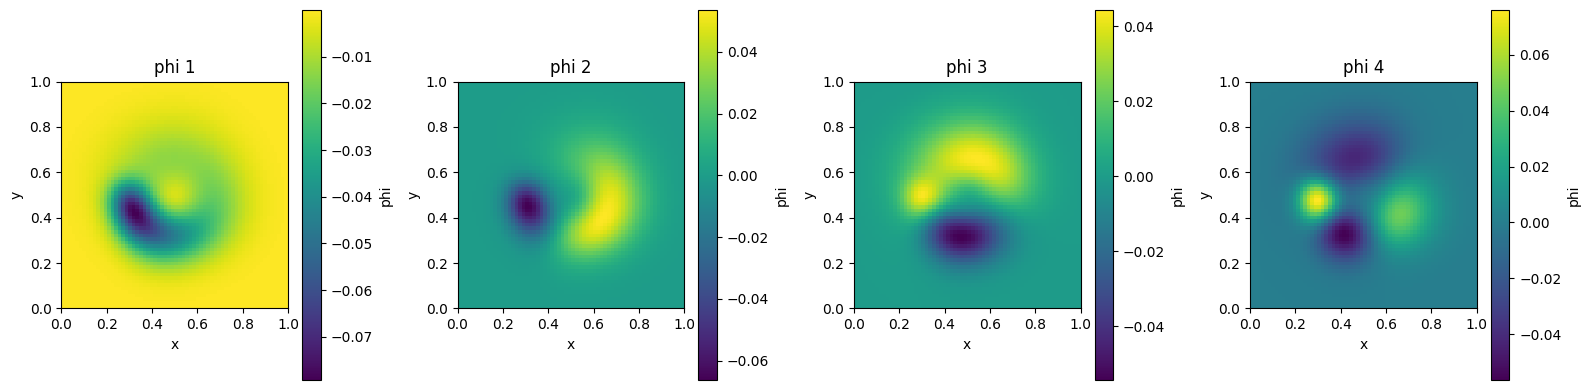

In [2]:
import numpy as np
import matplotlib.pyplot as plt

C = S.T @ S
K = C.shape[0]
print("C is", K, "x", K)

lam, psi = np.linalg.eigh(C)
order = np.argsort(lam)[::-1]
lam = lam[order]
psi = psi[:, order]

U, s, Vt = np.linalg.svd(S, full_matrices=False)

r = 20
phi = np.zeros((n, r))
for i in range(r):
  phi[:, i] = S @ psi[:, i] / np.sqrt(lam[i])
  if phi[:, i] @ U[:, i] < 0:
    phi[:, i] = -phi[:, i]

print("eigenvalues match sigma^2?", np.allclose(lam[:r], s[:r]*s[:r]))
for i in range(r):
  diff = np.max(np.abs(phi[:, i] - U[:, i]))
  print("mode", i + 1, ": sigma_i/sigma_1 =", f"{s[i]/s[0]:.2e}", ", max difference =", f"{diff:.2e}")

plt.figure(figsize=(16, 4))
for i in range(4):
  plt.subplot(1, 4, i + 1)
  plt.imshow(phi[:, i].reshape(nx, nx).T, origin='lower', extent=[0, 1, 0, 1])
  plt.colorbar(label="phi")
  plt.xlabel("x")
  plt.ylabel("y")
  plt.title("phi " + str(i + 1))
plt.tight_layout()
plt.show()

The eigenvalues for the matrix, C, match $σ_i^2$ and the modes for this matched the SVD for the leading modes. As $σ_i$ got smaller, the difference grew. This happened because dividing by $\sqrt{λ_i}$ made the rounding error blow up.

### Chapter 9 Exercise 6

offline time = 0.6342 s
online time (r = 10) = 0.0031 s
speedup = 205.5
r = 1 , relative error = 8.31e-01
r = 2 , relative error = 7.96e-01
r = 3 , relative error = 4.56e-01
r = 4 , relative error = 4.29e-01
r = 5 , relative error = 2.04e-01
r = 6 , relative error = 1.80e-01
r = 7 , relative error = 7.50e-02
r = 8 , relative error = 5.76e-02
r = 9 , relative error = 2.76e-02
r = 10 , relative error = 1.55e-02
r = 11 , relative error = 9.67e-03
r = 12 , relative error = 3.94e-03
r = 13 , relative error = 2.36e-03
r = 14 , relative error = 1.06e-03
r = 15 , relative error = 5.01e-04
r = 16 , relative error = 2.63e-04
r = 17 , relative error = 1.09e-04
r = 18 , relative error = 5.16e-05
r = 19 , relative error = 2.38e-05
r = 20 , relative error = 9.67e-06


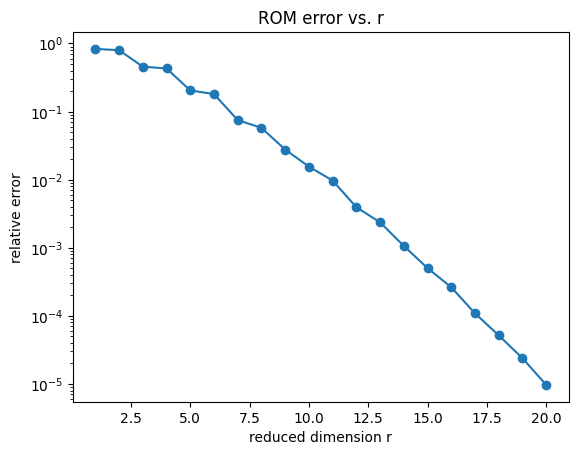

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.linalg import splu
import time

start = time.time()
M = sp.identity(n) - dt * A
solver = splu(M.tocsc())
u = S[:, 0].copy()
for k in range(steps):
  u = solver.solve(u)
U, s, Vt = np.linalg.svd(S, full_matrices=False)
Phi = U[:, :10]
Ar = Phi.T @ (A @ Phi)
offline_time = time.time() - start

start = time.time()
Mr = np.identity(10) - dt * Ar
a = Phi.T @ S[:, 0]
for k in range(steps):
  a = np.linalg.solve(Mr, a)
online_time = time.time() - start

print("offline time =", round(offline_time, 4), "s")
print("online time (r = 10) =", round(online_time, 4), "s")
print("speedup =", round(offline_time / online_time, 1))

r_values = list(range(1, 21))
errors = []
for r in r_values:
  Phi = U[:, :r]
  Ar = Phi.T @ (A @ Phi)
  Mr = np.identity(r) - dt * Ar
  a = Phi.T @ S[:, 0]
  S_rom = np.zeros((n, steps + 1))
  S_rom[:, 0] = Phi @ a
  for k in range(steps):
    a = np.linalg.solve(Mr, a)
    S_rom[:, k + 1] = Phi @ a
  err = np.linalg.norm(S_rom - S, 'fro') / np.linalg.norm(S, 'fro')
  errors.append(err)
  print("r =", r, ", relative error =", f"{err:.2e}")

plt.semilogy(r_values, errors, 'o-')
plt.xlabel("reduced dimension r")
plt.ylabel("relative error")
plt.title("ROM error vs. r")
plt.show()

The ROM error decreases as the r-value increases. This matched what the notes predicted: 18% at r=6, 1.5% at r=10, and $10^{-5}$ at r=20. The offline stage was slower because it depended on n while the online only depended on r. The speedup is hard to notice due to them both being under one second.

### Chapter 9 Exercise 10

A is 80 x 80 , kappa = 0.01 , a = 0.435 , s = 0.499
max Re eig(A) = -4.4152
max Re W(A) = 0.4003


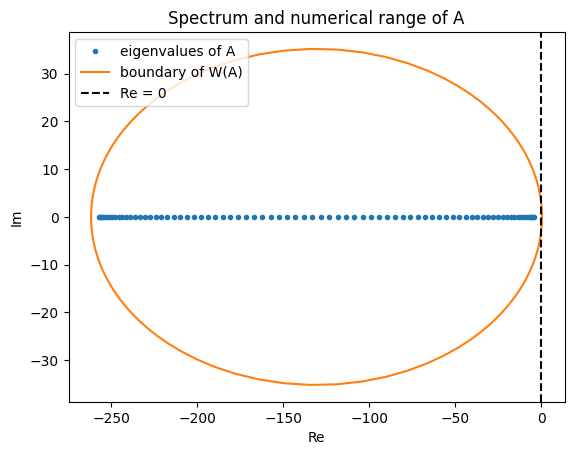

random subspaces: largest max Re eig(A_r) = -81.6553
unstable random ROMs: 0 out of 1000
POD subspace: max Re eig(A_r) = 0.4003
normal: max Re W = -4.4152
normal POD subspace: max Re eig(A_r) = -101.0367


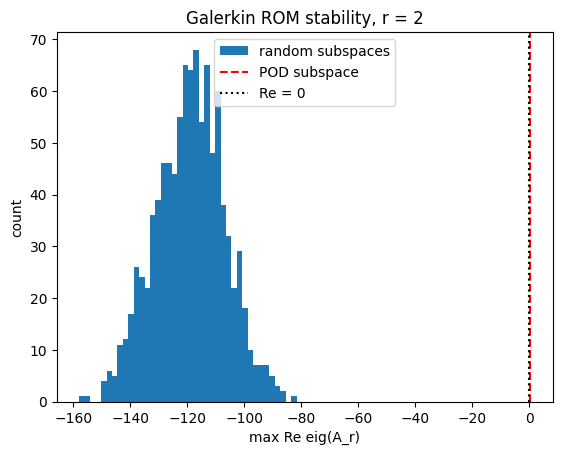

In [4]:
import numpy as np
import matplotlib.pyplot as plt

N = 80
h = 1 / (N + 1)
kappa = 0.01
a = 0.435
s = 0.499
x = np.linspace(h, 1 - h, N)
print("A is", N, "x", N, ", kappa =", kappa, ", a =", a, ", s =", s)

A = np.zeros((N, N))
for i in range(N):
  A[i, i] = -2 * kappa / (h*h) + s
  if i > 0:
    A[i, i - 1] = kappa / (h*h) + a / (2 * h)
  if i < N - 1:
    A[i, i + 1] = kappa / (h*h) - a / (2 * h)

eigs = np.linalg.eigvals(A)
print("max Re eig(A) =", round(np.max(eigs.real), 4))
print("max Re W(A) =", round(np.max(np.linalg.eigvalsh((A + A.T) / 2)), 4))

thetas = np.linspace(0, 2 * np.pi, 200)
W = []
for th in thetas:
  B = np.exp(1j * th) * A
  vals, vecs = np.linalg.eigh((B + B.conj().T) / 2)
  z = vecs[:, -1]
  W.append(z.conj() @ A @ z)
W = np.array(W)

plt.plot(eigs.real, eigs.imag, 'o', markersize=3, label="eigenvalues of A")
plt.plot(W.real, W.imag, '-', label="boundary of W(A)")
plt.axvline(0, color='k', linestyle='--', label="Re = 0")
plt.xlabel("Re")
plt.ylabel("Im")
plt.title("Spectrum and numerical range of A")
plt.legend()
plt.show()

rng = np.random.default_rng(352)
trials = 1000
rand_max = []
for t in range(trials):
  Q, _ = np.linalg.qr(rng.standard_normal((N, 2)))
  rand_max.append(np.max(np.linalg.eigvals(Q.T @ A @ Q).real))
print("random subspaces: largest max Re eig(A_r) =", round(np.max(rand_max), 4))
print("unstable random ROMs:", np.sum(np.array(rand_max) > 0), "out of", trials)

P, _ = np.linalg.qr(np.column_stack([np.sin(np.pi * x), np.sin(3 * np.pi * x)]))
pod_max = np.max(np.linalg.eigvals(P.T @ A @ P).real)
print("POD subspace: max Re eig(A_r) =", round(pod_max, 4))

A_normal = np.diag(np.linalg.eigvals(A))
print("normal: max Re W =", round(np.max(np.linalg.eigvalsh((A_normal + A_normal.conj().T) / 2)), 4))
print("normal POD subspace: max Re eig(A_r) =", round(np.max(np.linalg.eigvals(P.T @ A_normal @ P).real), 4))

plt.hist(rand_max, bins=40, label="random subspaces")
plt.axvline(pod_max, color='r', linestyle='--', label="POD subspace")
plt.axvline(0, color='k', linestyle=':', label="Re = 0")
plt.xlabel("max Re eig(A_r)")
plt.ylabel("count")
plt.title("Galerkin ROM stability, r = 2")
plt.legend()
plt.show()

The eigenvalues of A are all in the left half-plane, but W(A) crosses into Re > 0. This happens because A is non-normal. The random subspaces all gave stable ROMs. In contrast, the POD subspace gave an unstable one. For the normal version, W(A) stayed in the left half-plane.

### Chapter 9 Exercise 13

n = 4096 , r = 8 , training eps: [0.0002  0.00038 0.00074 0.00141 0.00271 0.00521 0.01   ]
pooled snapshot matrix is 4096 x 847
convective basis: min = 0.046 , max = 0.188
diffusive basis: min = 0.027 , max = 0.208
global basis: min = 0.045 , max = 0.132
affine A_r matches direct projection? True


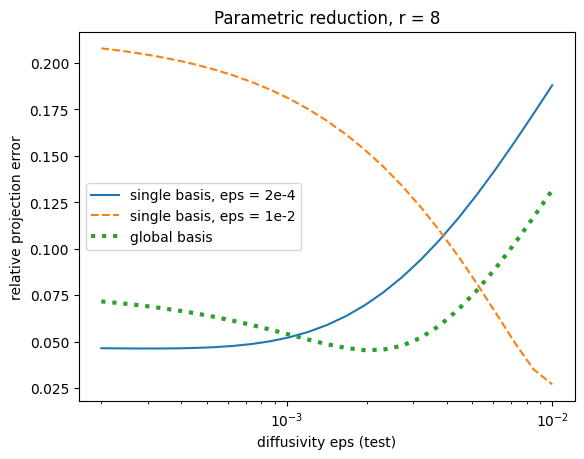

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.linalg import splu

nx = 64
h = 1 / (nx + 1)
n = nx * nx
omega = 2 * np.pi
steps = 120
dt = 1 / steps
r = 8

grid = np.linspace(h, 1 - h, nx)
xx, yy = np.meshgrid(grid, grid, indexing='ij')
xv = xx.flatten()
yv = yy.flatten()
vx = -omega * (yv - 0.5)
vy = omega * (xv - 0.5)

A_adv = sp.lil_matrix((n, n))
A_lap = sp.lil_matrix((n, n))
for i in range(nx):
  for j in range(nx):
    k = i * nx + j
    A_lap[k, k] = -4 / (h*h)
    A_adv[k, k] = -abs(vx[k]) / h - abs(vy[k]) / h
    if i > 0:
      A_lap[k, k - nx] = 1 / (h*h)
      A_adv[k, k - nx] = max(vx[k], 0) / h
    if i < nx - 1:
      A_lap[k, k + nx] = 1 / (h*h)
      A_adv[k, k + nx] = max(-vx[k], 0) / h
    if j > 0:
      A_lap[k, k - 1] = 1 / (h*h)
      A_adv[k, k - 1] = max(vy[k], 0) / h
    if j < nx - 1:
      A_lap[k, k + 1] = 1 / (h*h)
      A_adv[k, k + 1] = max(-vy[k], 0) / h
A_adv = A_adv.tocsc()
A_lap = A_lap.tocsc()

u0 = np.exp(-((xv - 0.3)*(xv - 0.3) + (yv - 0.5)*(yv - 0.5)) / (2 * 0.06*0.06))

def fom(eps):
  M = sp.identity(n) - dt * (A_adv + eps * A_lap)
  solver = splu(M.tocsc())
  u = u0.copy()
  S = np.zeros((n, steps + 1))
  S[:, 0] = u
  for k in range(steps):
    u = solver.solve(u)
    S[:, k + 1] = u
  return S

def proj_err(Phi, S):
  return np.linalg.norm(S - Phi @ (Phi.T @ S), 'fro') / np.linalg.norm(S, 'fro')

eps_train = np.geomspace(2e-4, 1e-2, 7)
eps_test = np.geomspace(2e-4, 1e-2, 25)
print("n =", n, ", r =", r, ", training eps:", np.round(eps_train, 5))

U, s, Vt = np.linalg.svd(fom(2e-4), full_matrices=False)
Phi_conv = U[:, :r]
U, s, Vt = np.linalg.svd(fom(1e-2), full_matrices=False)
Phi_diff = U[:, :r]

S_all = np.hstack([fom(eps) for eps in eps_train])
U, s, Vt = np.linalg.svd(S_all, full_matrices=False)
Phi_glob = U[:, :r]
print("pooled snapshot matrix is", S_all.shape[0], "x", S_all.shape[1])

err_conv = []
err_diff = []
err_glob = []
for eps in eps_test:
  S = fom(eps)
  err_conv.append(proj_err(Phi_conv, S))
  err_diff.append(proj_err(Phi_diff, S))
  err_glob.append(proj_err(Phi_glob, S))

print("convective basis: min =", round(min(err_conv), 3), ", max =", round(max(err_conv), 3))
print("diffusive basis: min =", round(min(err_diff), 3), ", max =", round(max(err_diff), 3))
print("global basis: min =", round(min(err_glob), 3), ", max =", round(max(err_glob), 3))

Ar_adv = Phi_glob.T @ (A_adv @ Phi_glob)
Ar_lap = Phi_glob.T @ (A_lap @ Phi_glob)
eps = 1e-3
Ar_online = Ar_adv + eps * Ar_lap
Ar_direct = Phi_glob.T @ ((A_adv + eps * A_lap) @ Phi_glob)
print("affine A_r matches direct projection?", np.allclose(Ar_online, Ar_direct))

plt.semilogx(eps_test, err_conv, '-', label="single basis, eps = 2e-4")
plt.semilogx(eps_test, err_diff, '--', label="single basis, eps = 1e-2")
plt.semilogx(eps_test, err_glob, ':', linewidth=3, label="global basis")
plt.xlabel("diffusivity eps (test)")
plt.ylabel("relative projection error")
plt.title("Parametric reduction, r = 8")
plt.legend()
plt.show()

The single basis was most accurate near its own ϵ but it got worse as it got to the end. The global basis was pretty accurate across the whole range, having the lowest max relative projection error. The affline check was good, so $A_r(ϵ)$ can be built online. You would just need to add two 8 x 8 matrices.

### Chapter 9 Exercise 14

A is 80 x 80 , kappa = 0.01 , a = 0.435 , s = 0.499 , r = 2 , dt = 0.1 , T = 20.0
eig(A_r) = [ 0.40031633 -0.3882627 ]
max Re eig(A) = -4.4152
FOM energy at T = 3.39e-26
ROM energy at T = 2.25e+04


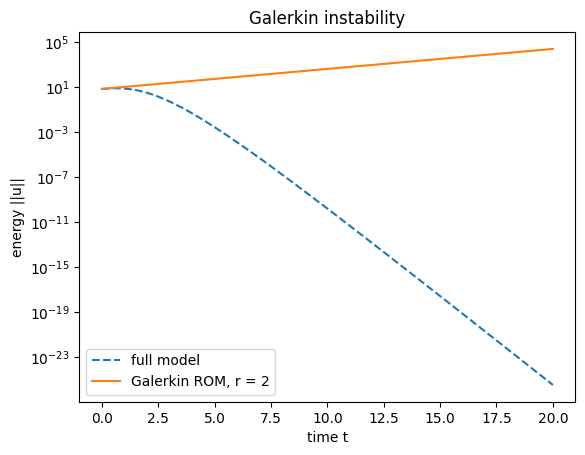

In [6]:
import numpy as np
import matplotlib.pyplot as plt

N = 80
h = 1 / (N + 1)
kappa = 0.01
a = 0.435
s = 0.499
x = np.linspace(h, 1 - h, N)
r = 2
dt = 0.1
steps = 200
print("A is", N, "x", N, ", kappa =", kappa, ", a =", a, ", s =", s, ", r =", r, ", dt =", dt, ", T =", dt * steps)

A = np.zeros((N, N))
for i in range(N):
  A[i, i] = -2 * kappa / (h*h) + s
  if i > 0:
    A[i, i - 1] = kappa / (h*h) + a / (2 * h)
  if i < N - 1:
    A[i, i + 1] = kappa / (h*h) - a / (2 * h)

P, _ = np.linalg.qr(np.column_stack([np.sin(np.pi * x), np.sin(3 * np.pi * x)]))
Ar = P.T @ A @ P
print("eig(A_r) =", np.linalg.eigvals(Ar))
print("max Re eig(A) =", round(np.max(np.linalg.eigvals(A).real), 4))

M = np.identity(N) - dt * A
Mr = np.identity(r) - dt * Ar

u = np.sin(np.pi * x)
c = P.T @ u
t = np.zeros(steps + 1)
fom_energy = np.zeros(steps + 1)
rom_energy = np.zeros(steps + 1)
fom_energy[0] = np.linalg.norm(u)
rom_energy[0] = np.linalg.norm(P @ c)
for k in range(steps):
  u = np.linalg.solve(M, u)
  c = np.linalg.solve(Mr, c)
  t[k + 1] = (k + 1) * dt
  fom_energy[k + 1] = np.linalg.norm(u)
  rom_energy[k + 1] = np.linalg.norm(P @ c)

print("FOM energy at T =", f"{fom_energy[-1]:.2e}")
print("ROM energy at T =", f"{rom_energy[-1]:.2e}")

plt.semilogy(t, fom_energy, '--', label="full model")
plt.semilogy(t, rom_energy, '-', label="Galerkin ROM, r = 2")
plt.xlabel("time t")
plt.ylabel("energy ||u||")
plt.title("Galerkin instability")
plt.legend()
plt.show()

I used backward Euler with a Δt=0.1 to T=20 and $u_o$=sin(πx). The energy in this model decayed, but r=2 Galerkin ROM's energy grows. This happens due to the reduced operator having a positive eigenvalue.

### Chapter 9 Exercise 16

A is 80 x 80 , kappa = 0.01 , a = 0.435 , s = 0.499 , r = 2 , dt = 0.5 , T = 20.0
Galerkin A_r eigenvalues: [ 0.40031633 -0.3882627 ]
LSPG reduced operator eigenvalues: [1.09461461 5.50604939]
Galerkin step |eig|: [1.25024718 0.83742881]
LSPG step |eig|: [0.73073144 0.2168688 ]
energy at T: FOM = 5.46e-15 , Galerkin = 4.83e+04 , LSPG = 2.26e-05


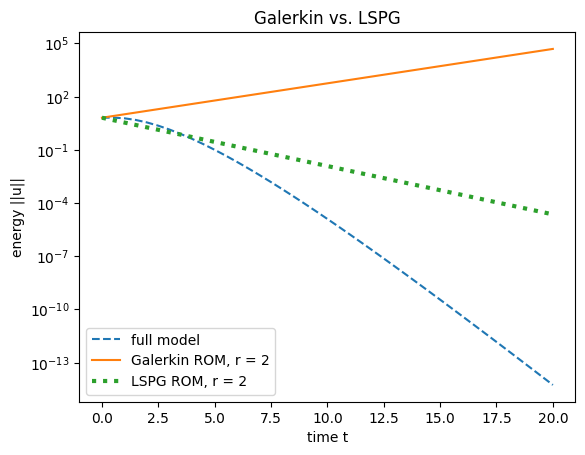

In [7]:
import numpy as np
import matplotlib.pyplot as plt

N = 80
h = 1 / (N + 1)
kappa = 0.01
a = 0.435
s = 0.499
x = np.linspace(h, 1 - h, N)
r = 2
dt = 0.5
steps = 40
print("A is", N, "x", N, ", kappa =", kappa, ", a =", a, ", s =", s, ", r =", r, ", dt =", dt, ", T =", dt * steps)

A = np.zeros((N, N))
for i in range(N):
  A[i, i] = -2 * kappa / (h*h) + s
  if i > 0:
    A[i, i - 1] = kappa / (h*h) + a / (2 * h)
  if i < N - 1:
    A[i, i + 1] = kappa / (h*h) - a / (2 * h)

P, _ = np.linalg.qr(np.column_stack([np.sin(np.pi * x), np.sin(3 * np.pi * x)]))
M = np.identity(N) - dt * A

Mr_gal = P.T @ M @ P
G_gal = np.linalg.inv(Mr_gal)

MP = M @ P
Mr_lspg = MP.T @ MP
G_lspg = np.linalg.solve(Mr_lspg, MP.T @ P)

print("Galerkin A_r eigenvalues:", np.linalg.eigvals(P.T @ A @ P))
print("LSPG reduced operator eigenvalues:", np.linalg.eigvalsh(Mr_lspg))
print("Galerkin step |eig|:", np.abs(np.linalg.eigvals(G_gal)))
print("LSPG step |eig|:", np.abs(np.linalg.eigvals(G_lspg)))

u = np.sin(np.pi * x)
c_gal = P.T @ u
c_lspg = P.T @ u
t = np.zeros(steps + 1)
fom_energy = np.zeros(steps + 1)
gal_energy = np.zeros(steps + 1)
lspg_energy = np.zeros(steps + 1)
fom_energy[0] = np.linalg.norm(u)
gal_energy[0] = np.linalg.norm(P @ c_gal)
lspg_energy[0] = np.linalg.norm(P @ c_lspg)
for k in range(steps):
  u = np.linalg.solve(M, u)
  c_gal = G_gal @ c_gal
  c_lspg = G_lspg @ c_lspg
  t[k + 1] = (k + 1) * dt
  fom_energy[k + 1] = np.linalg.norm(u)
  gal_energy[k + 1] = np.linalg.norm(P @ c_gal)
  lspg_energy[k + 1] = np.linalg.norm(P @ c_lspg)

print("energy at T: FOM =", f"{fom_energy[-1]:.2e}", ", Galerkin =", f"{gal_energy[-1]:.2e}", ", LSPG =", f"{lspg_energy[-1]:.2e}")

plt.semilogy(t, fom_energy, '--', label="full model")
plt.semilogy(t, gal_energy, '-', label="Galerkin ROM, r = 2")
plt.semilogy(t, lspg_energy, ':', linewidth=3, label="LSPG ROM, r = 2")
plt.xlabel("time t")
plt.ylabel("energy ||u||")
plt.title("Galerkin vs. LSPG")
plt.legend()
plt.show()

The Galerkin reduced operator has a positive eigenvalue. In contrast, LSPG reduced operator is SPD with all positive eigenvalues. The step matrix has |eig|<1 and therefore can't blow up. In the energy plot, Galerkin grows while LSPG is bounded and decays like the FOM. I used a Δt of 0.5.

## Chapter 10

### Chapter 10 Exercise 2

data is 19800 x 120 , dt = 0.05 , r = 7
|lambda| = 1.0 , f = 0.0 , |b| = 26.15
|lambda| = 1.0 , f = 0.5 , |b| = 17.21
|lambda| = 1.0 , f = -0.5 , |b| = 17.21
|lambda| = 1.0 , f = 1.0 , |b| = 3.46
|lambda| = 1.0 , f = -1.0 , |b| = 3.46
|lambda| = 1.0 , f = 1.5 , |b| = 0.3
|lambda| = 1.0 , f = -1.5 , |b| = 0.3


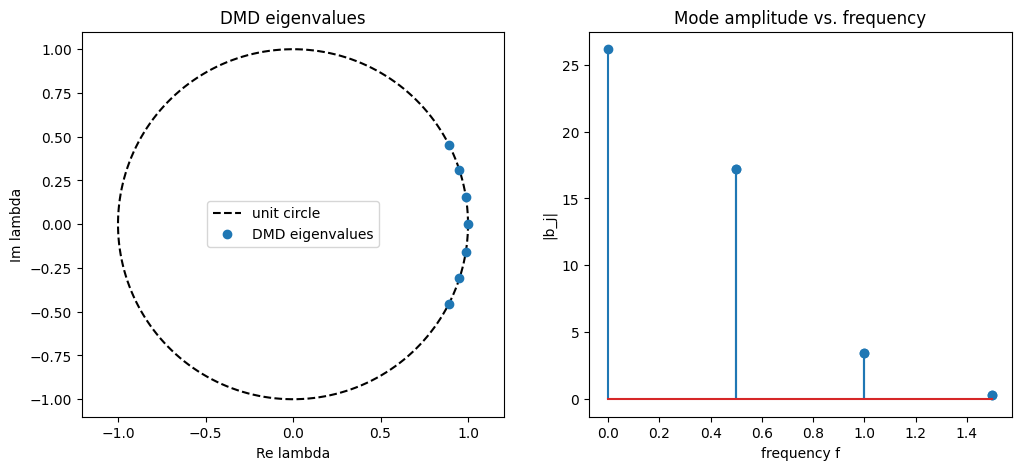

In [8]:
import numpy as np
import matplotlib.pyplot as plt

Lx = 11
Ly = 4.5
nx = 220
ny = 90
U = 1
a = 2
b = 0.5
sigma = 0.32
Gamma = 1
dt = 0.05
m = 120
r = 7

xg = np.linspace(0, Lx, nx)
yg = np.linspace(-Ly / 2, Ly / 2, ny)
xx, yy = np.meshgrid(xg, yg, indexing='ij')

def vorticity(t):
  w = np.zeros((nx, ny))
  for k in range(-8, 8):
    xp = U * t + k * a
    xm = U * t + (k + 0.5) * a
    w += Gamma * np.exp(-((xx - xp)*(xx - xp) + (yy - b)*(yy - b)) / (2 * sigma*sigma))
    w -= Gamma * np.exp(-((xx - xm)*(xx - xm) + (yy + b)*(yy + b)) / (2 * sigma*sigma))
  return (np.tanh(xx / 0.6) * w).flatten()

D = np.zeros((nx * ny, m))
for k in range(m):
  D[:, k] = vorticity(k * dt)
print("data is", D.shape[0], "x", D.shape[1], ", dt =", dt, ", r =", r)

X = D[:, :-1]
Xp = D[:, 1:]
Uu, s, Vt = np.linalg.svd(X, full_matrices=False)
Ur = Uu[:, :r]
Sr = np.diag(s[:r])
Vr = Vt[:r, :].T
At = Ur.T @ Xp @ Vr @ np.linalg.inv(Sr)
lam, Wv = np.linalg.eig(At)
Phi = Xp @ Vr @ np.linalg.inv(Sr) @ Wv / lam
omega = np.log(lam) / dt
freq = omega.imag / (2 * np.pi)
bvec = np.linalg.lstsq(Phi, D[:, 0], rcond=None)[0]

for j in range(r):
  print("|lambda| =", round(abs(lam[j]), 4), ", f =", round(freq[j], 4), ", |b| =", round(abs(bvec[j]), 2))

th = np.linspace(0, 2 * np.pi, 200)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(np.cos(th), np.sin(th), 'k--', label="unit circle")
plt.plot(lam.real, lam.imag, 'o', label="DMD eigenvalues")
plt.xlabel("Re lambda")
plt.ylabel("Im lambda")
plt.title("DMD eigenvalues")
plt.axis('equal')
plt.legend()
plt.subplot(1, 2, 2)
plt.stem(np.abs(freq), np.abs(bvec))
plt.xlabel("frequency f")
plt.ylabel("|b_j|")
plt.title("Mode amplitude vs. frequency")
plt.show()

The DMD eigenvalues all appear on the unit circle, therefore the modes don't grow or decay. The frequencies matched what the notes predicted: the mean, the shedding frequency $f_s$=0.5, and its harmonics.

### Chapter 10 Exercise 5

trained on 60 snapshots, t = 0 to 2.95 , r = 7
|lambda| = [1.       1.       1.       1.       1.       0.999999 0.999999]
true data is 19800 x 240 , t = 0 to 12.0
relative error at end of training: 2.90e-04 , t = 6: 3.68e-04 , t = 12: 3.34e-04
probe at x = 7.53 , y = 0.53


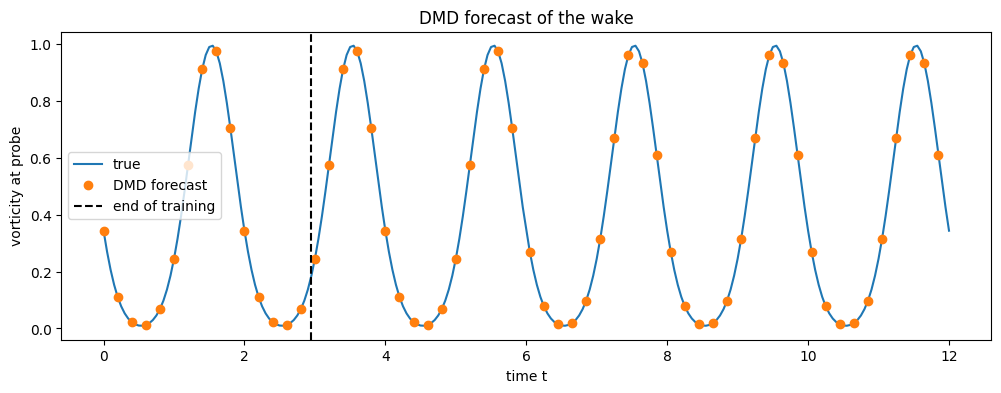

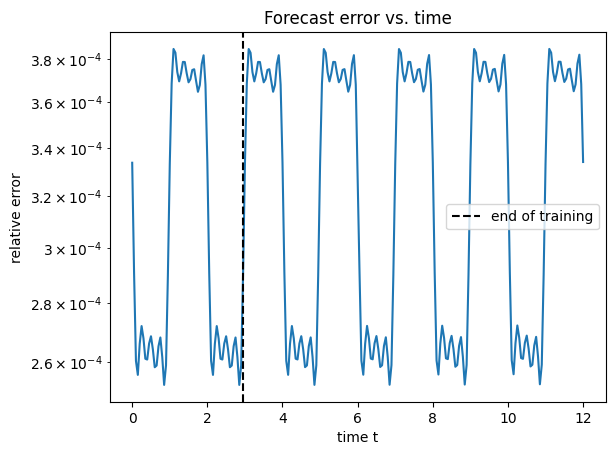

In [9]:
import numpy as np
import matplotlib.pyplot as plt

m_train = 60
X = D[:, :m_train - 1]
Xp = D[:, 1:m_train]
Uu, s, Vt = np.linalg.svd(X, full_matrices=False)
Ur = Uu[:, :r]
Sr = np.diag(s[:r])
Vr = Vt[:r, :].T
At = Ur.T @ Xp @ Vr @ np.linalg.inv(Sr)
lam, Wv = np.linalg.eig(At)
Phi = Xp @ Vr @ np.linalg.inv(Sr) @ Wv / lam
bvec = np.linalg.lstsq(Phi, D[:, 0], rcond=None)[0]
print("trained on", m_train, "snapshots, t = 0 to", (m_train - 1) * dt, ", r =", r)
print("|lambda| =", np.round(np.abs(lam), 6))

D_new = np.zeros((nx * ny, 120))
for k in range(120):
  D_new[:, k] = vorticity(6 + (k + 1) * dt)
D_true = np.hstack([D, D_new])
t = np.concatenate([np.arange(120) * dt, 6 + (np.arange(120) + 1) * dt])
K = len(t)
print("true data is", D_true.shape[0], "x", K, ", t = 0 to", round(t[-1], 2))

D_pred = np.zeros((nx * ny, K))
for j in range(K):
  k = round(t[j] / dt)
  D_pred[:, j] = (Phi @ (lam**k * bvec)).real

err = np.linalg.norm(D_pred - D_true, axis=0) / np.linalg.norm(D_true, axis=0)
print("relative error at end of training:", f"{err[m_train - 1]:.2e}", ", t = 6:", f"{err[119]:.2e}", ", t = 12:", f"{err[-1]:.2e}")

probe = 150 * ny + 55
print("probe at x =", round(xg[150], 2), ", y =", round(yg[55], 2))

plt.figure(figsize=(12, 4))
plt.plot(t, D_true[probe, :], '-', label="true")
plt.plot(t[::4], D_pred[probe, ::4], 'o', label="DMD forecast")
plt.axvline((m_train - 1) * dt, color='k', linestyle='--', label="end of training")
plt.xlabel("time t")
plt.ylabel("vorticity at probe")
plt.title("DMD forecast of the wake")
plt.legend()
plt.show()

plt.semilogy(t, err)
plt.axvline((m_train - 1) * dt, color='k', linestyle='--', label="end of training")
plt.xlabel("time t")
plt.ylabel("relative error")
plt.title("Forecast error vs. time")
plt.legend()
plt.show()

The forecast appears to stay on the true signal for several periods past training, and the error stayed small through t=12. The small error is due to r=7 only keeping up to the third harmonic. Over a much longer forecast, the prediction would start to drift.

### Chapter 10 Exercise 10

mu = -0.05 , lambda = -1 , x(0) = ( 1.5 , -1 ), dt = 0.05 , snapshots = 161
plain DMD continuous eigenvalues: [-0.05   -1.2077]
Koopman matrix K:
[[ 0.9975 -0.     -0.    ]
 [ 0.      0.9512  0.0486]
 [ 0.     -0.      0.995 ]]
EDMD continuous eigenvalues: [-1.   -0.1  -0.05]
true: mu = -0.05 , lambda = -1 , 2mu = -0.1
max |x2 error| plain DMD: 3.67e-01
max |x2 error| EDMD: 4.69e-13


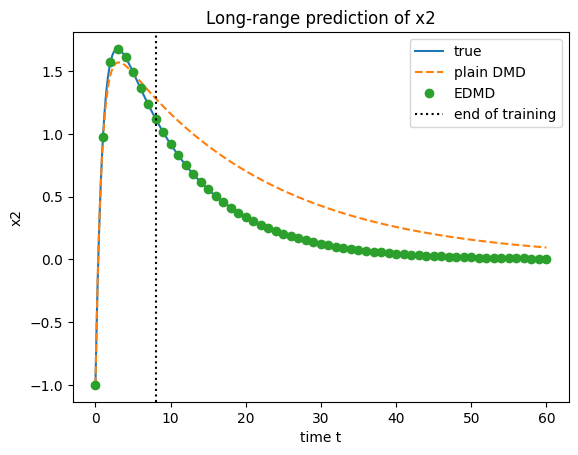

In [10]:
import numpy as np
import matplotlib.pyplot as plt

mu = -0.05
lam = -1
x10 = 1.5
x20 = -1
dt = 0.05
T = 8
t = np.arange(0, T + dt / 2, dt)
m = len(t)
c = lam / (lam - 2 * mu)
print("mu =", mu, ", lambda =", lam, ", x(0) = (", x10, ",", x20, "), dt =", dt, ", snapshots =", m)

x1 = x10 * np.exp(mu * t)
x2 = c * x1 * x1 + (x20 - c * x10 * x10) * np.exp(lam * t)
Xall = np.vstack([x1, x2])

A = Xall[:, 1:] @ np.linalg.pinv(Xall[:, :-1])
print("plain DMD continuous eigenvalues:", np.round(np.log(np.linalg.eigvals(A)) / dt, 4))

Y = np.vstack([x1, x2, x1 * x1])
K = Y[:, 1:] @ np.linalg.pinv(Y[:, :-1])
print("Koopman matrix K:")
print(np.round(K, 4))
print("EDMD continuous eigenvalues:", np.round(np.sort(np.log(np.linalg.eigvals(K)) / dt), 4))
print("true: mu =", mu, ", lambda =", lam, ", 2mu =", 2 * mu)

T_long = 60
t_long = np.arange(0, T_long + dt / 2, dt)
x1_true = x10 * np.exp(mu * t_long)
x2_true = c * x1_true * x1_true + (x20 - c * x10 * x10) * np.exp(lam * t_long)

x_dmd = np.zeros((2, len(t_long)))
y_edmd = np.zeros((3, len(t_long)))
x_dmd[:, 0] = [x10, x20]
y_edmd[:, 0] = [x10, x20, x10 * x10]
for k in range(len(t_long) - 1):
  x_dmd[:, k + 1] = A @ x_dmd[:, k]
  y_edmd[:, k + 1] = K @ y_edmd[:, k]

print("max |x2 error| plain DMD:", f"{np.max(np.abs(x_dmd[1] - x2_true)):.2e}")
print("max |x2 error| EDMD:", f"{np.max(np.abs(y_edmd[1] - x2_true)):.2e}")

plt.plot(t_long, x2_true, '-', label="true")
plt.plot(t_long, x_dmd[1], '--', label="plain DMD")
plt.plot(t_long[::20], y_edmd[1, ::20], 'o', label="EDMD")
plt.axvline(T, color='k', linestyle=':', label="end of training")
plt.xlabel("time t")
plt.ylabel("x2")
plt.title("Long-range prediction of x2")
plt.legend()
plt.show()

Plain DMD got μ right but got λ wrong. This happens due to it not being able to represent the $x_1^2$ coupling. EDMD was able to recover μ, λ, and 2μ exactly. In the plot, plain DMD drifts off while EDMD stays exact.